# [WEEK 7] A/B Test Design — Assignment (학생용)

**과제 유형: B. 도구 활용형** (생성형 AI 사용 가능, 판단·검증·해석은 직접)

## 과제 목적

숙박 예약 앱의 분석팀이 **"promotion 채널 사용자의 목록 → 상세 전환율이 유독 낮다"**는 진단을 넘겨줬습니다.
이번 과제에서는 이 문제를 개선할 아이디어를 **검증 가능한 실험으로 설계**하고, **여러분이 쓴 설계서 그대로 실험을 돌려** 결과를 판정합니다.

과제의 무게중심은 코드가 아니라 **설계**입니다. 설계서에 적은 값(지표, 배정 단위, 표본, 기간, 중단 규칙)이 실제 실험 결과를 결정하고, 결과를 보기 전에 정한 **판정 규칙**대로 배포 여부를 결정해야 합니다.

> **진단 메모 → 처방 선택 → 가설 → 지표 → 배정 → 표본·기간 → 사전 판정 규칙 → 실행 → SRM 확인 → 검정 → 판정**

---

## 📝 기술블로그 활용 안내

이번 글은 **"진단 결과를 받아서, 개선안을 실험으로 검증한다"**는 흐름으로 작성해주세요. 다음 그로스 세션 글과 이어지는 시리즈가 됩니다.

- **Part 0**의 Q0 답변 → 글의 도입부 ("왜 가격 표시 오류 수정은 실험하지 않고, 화면 개선만 실험했는가")
- **Part 1.2 ~ 1.7**의 설계서 → 본문 "실험 설계" 섹션 (특히 1.5의 MDE–기간 그래프와 선택 근거)
- **Part 2.2 ~ 2.3**의 결과 표·그래프와 결정 메모 → 본문 "결과와 의사결정" 섹션
- (선택) **Part 3** 심화 결과 → "설계가 달랐다면?" 섹션

코드를 나열하지 말고, **왜 그렇게 설계했고 결과를 어떻게 판정했는지**를 중심으로 써주세요.

---

## 🤖 생성형 AI 활용 안내

AI 사용은 가능합니다. 다만 이 과제는 **본인이 고른 설계값**(아이디어, 지표, 대상, 기간, 중단 규칙)에 따라 실험 결과가 달라지기 때문에, AI의 일반론으로는 답이 맞지 않습니다.

- 코드 문법, 시각화, 오류 수정, 개념 확인에 활용 가능
- 수치와 판정은 반드시 **본인 데이터로 직접 계산한 결과**로
- 마지막 셀에 **AI 활용 방법과 대화 내역**을 꼭 붙여주세요

> 이번 과제에서 가장 많이 감점되는 실수: **결과를 보고 나서 판정 기준을 바꾸는 것**입니다.

---
# 0. 환경 설정

1. 라이브러리 셀 → **실험 시뮬레이터** 셀 → **분석 도우미** 셀을 차례로 실행하세요. (세 셀 모두 수정하지 마세요)
2. 그다음 데이터 생성 셀을 실행하세요. `SEED`는 고정값이라 모두 같은 사용자 데이터를 씁니다.
   **결과를 다르게 만드는 건 여러분의 설계**입니다.

데이터는 교육용 synthetic dataset입니다. 가상의 숙박 예약 앱 로그이며, 이후 그로스 세션 과제에서도 같은 앱이 등장합니다.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [ ]:
#@title ⚙️ 실험 시뮬레이터 — 수정하지 말고 실행하세요
# 이 셀은 "실험 전 로그"와 "여러분의 설계대로 돌아가는 A/B 실험 데이터"를 만들어 줍니다.
# 가상의 숙박 예약 앱 로그입니다. (이후 그로스 세션 과제에서도 같은 앱이 등장합니다)
import json, base64, math
import numpy as np
import pandas as pd

_CFG = json.loads(base64.b64decode(
    "eyJBIjogeyJkZXRhaWxfcHJvbW8iOiAwLjA0MiwgImRldGFpbF9vdGhlciI6IDAuMDA2LCAicm9vbSI6IDAuMDEs"
    "ICJyb29tX3Byb21vIjogMC4wMSwgImNvbXBsZXRlIjogMC4wLCAibm92ZWx0eSI6IDAuMCwgImFtb3VudCI6IDEu"
    "MCwgImNhbmNlbCI6IDAuMH0sICJCIjogeyJkZXRhaWxfcHJvbW8iOiAwLjA3LCAiZGV0YWlsX290aGVyIjogMC4w"
    "NDUsICJyb29tIjogLTAuMDY1LCAicm9vbV9wcm9tbyI6IC0wLjA2NSwgImNvbXBsZXRlIjogMC4wLCAibm92ZWx0"
    "eSI6IDAuMCwgImFtb3VudCI6IDEuMCwgImNhbmNlbCI6IDAuMH0sICJDIjogeyJkZXRhaWxfcHJvbW8iOiAwLjAx"
    "MiwgImRldGFpbF9vdGhlciI6IDAuMDA2LCAicm9vbSI6IDAuMCwgInJvb21fcHJvbW8iOiAwLjAsICJjb21wbGV0"
    "ZSI6IDAuMDMsICJub3ZlbHR5IjogMC4xLCAiYW1vdW50IjogMC45MiwgImNhbmNlbCI6IDAuMDR9fQ=="
).decode())

_CHANNELS = ["organic", "paid_search", "promotion", "referral"]
_CH_P = [0.38, 0.27, 0.20, 0.15]
_DEVICES = ["android", "ios", "web"]
_DV_P = [0.41, 0.38, 0.21]
_P_LIST = 0.925
_P_DETAIL = {"organic": 0.62, "paid_search": 0.60, "promotion": 0.49, "referral": 0.64}
_P_ROOM, _P_CHECKOUT = 0.66, 0.56
_PAY = {"ios": ([0.38, 0.12, 0.50]), "android": ([0.50, 0.15, 0.35]), "web": ([0.60, 0.18, 0.22])}
_METHODS = ["card", "bank_transfer", "simple_pay"]
_P_COMPLETE = {"card": 0.70, "bank_transfer": 0.66, "simple_pay": 0.69}
_POOL = 120_000                 # 앱 전체 활성 사용자
_DAILY_SESSIONS = 10_000        # 하루 검색 세션 (전체)
_EXP_START = pd.Timestamp("2026-03-02")
_CAMPAIGN_DAY = 8               # 실험 8일차부터 promotion 채널 대규모 광고 캠페인

METRICS = {
    # 지표 이름: (분자 컬럼, 분모 컬럼)  ※ 모두 "세션 단위 비율"
    "list_to_detail":       ("detail_view", "list_view"),
    "detail_to_room":       ("room_select", "detail_view"),
    "checkout_to_complete": ("payment_complete", "checkout"),
    "search_to_complete":   ("payment_complete", "search"),
    "cancel_rate":          ("cancelled", "payment_complete"),
    "revenue_per_search":   ("net_amount", "search"),
}


def _sig(x):
    return 1 / (1 + np.exp(-x))


def _logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def _users(rng):
    n = _POOL
    u = pd.DataFrame({
        "user_id": np.arange(200001, 200001 + n),
        "channel": rng.choice(_CHANNELS, size=n, p=_CH_P),
        "device": rng.choice(_DEVICES, size=n, p=_DV_P),
        "user_type": rng.choice(["leisure", "business"], size=n, p=[0.72, 0.28]),
    })
    # 방문 빈도(사람마다 다름)와 구매 성향(사람마다 다름)
    u["visit_rate"] = rng.gamma(0.5, 1.0, size=n)
    u["visit_rate"] *= _DAILY_SESSIONS / u["visit_rate"].sum()
    u["propensity"] = rng.normal(0, 1.0, size=n)
    u["old_browser"] = (u["device"] == "web") & (rng.random(n) < 0.45)
    u.loc[u["old_browser"], "propensity"] -= 0.6
    return u


def _simulate_sessions(rng, users, days, start, group=None, idea=None, target="promotion",
                       campaign_from=None, unit="user"):
    """days일 동안의 세션을 만든다. group: user_id -> 'A'/'B' (None이면 처치 없음)"""
    lam0 = users["visit_rate"].to_numpy()
    is_promo_user = (users["channel"] == "promotion").to_numpy()
    rows = []
    cfg = _CFG.get(idea, None) if idea else None
    for d in range(days):
        camp = campaign_from is not None and (d + 1) >= campaign_from
        lam = np.where(is_promo_user & camp, lam0 * 1.4, lam0)
        cnt = rng.poisson(lam)
        idx = np.repeat(np.arange(len(users)), cnt)
        if len(idx) == 0:
            continue
        s = users.iloc[idx].reset_index(drop=True)
        n = len(s)
        s["day"] = d + 1
        s["session_start"] = (start + pd.to_timedelta(d, unit="D")
                              + pd.to_timedelta(rng.integers(8 * 3600, 23 * 3600, size=n), unit="s"))
        # 처치 여부
        treat = np.zeros(n, dtype=bool)
        if group is not None:
            if unit == "session":
                in_exp = s["user_id"].isin(group.index).to_numpy()
                coin = rng.random(n) < 0.5
                s["group"] = np.where(in_exp, np.where(coin, "B", "A"), None)
            else:
                s["group"] = s["user_id"].map(group)
            treat = (s["group"] == "B").to_numpy()
        promo = (s["channel"] == "promotion").to_numpy()
        prop = s["propensity"].to_numpy()
        if camp:   # 캠페인으로 들어온 세션은 구매 의도가 상대적으로 약함
            prop = prop - np.where(promo, 0.35, 0.0)

        # 효과 크기 (세션 단위 배정이면 같은 사람이 두 화면을 오가며 효과가 일부 희석됨)
        dil = 0.8 if unit == "session" else 1.0
        e_detail = np.zeros(n); e_room = np.zeros(n); e_comp = np.zeros(n)
        if cfg is not None:
            nov = cfg["novelty"] * math.exp(-(d) / 4.0)
            e_detail = np.where(promo, cfg["detail_promo"] + nov, cfg["detail_other"] + nov * 0.5) * dil
            e_room = np.where(promo, cfg["room_promo"], cfg["room"]) * dil
            e_comp = np.full(n, cfg["complete"]) * dil
            e_detail *= treat; e_room *= treat; e_comp *= treat

        list_ = rng.random(n) < _P_LIST
        p_det = s["channel"].map(_P_DETAIL).to_numpy() + e_detail
        detail = list_ & (rng.random(n) < _sig(_logit(p_det) + prop))
        room = detail & (rng.random(n) < _sig(_logit(_P_ROOM + e_room) + 0.6 * prop))
        checkout = room & (rng.random(n) < _sig(_logit(np.full(n, _P_CHECKOUT)) + 0.4 * prop))
        dev = s["device"].to_numpy()
        pm = np.empty(n, dtype=object)
        for dv in _DEVICES:
            m = dev == dv
            pm[m] = rng.choice(_METHODS, size=m.sum(), p=_PAY[dv])
        pc = np.vectorize(_P_COMPLETE.get)(pm).astype(float) + np.where(dev == "web", 0.02, 0)
        bug = (dev == "ios") & (pm == "simple_pay")
        broken = bug & (s["session_start"] >= pd.Timestamp("2026-04-01")).to_numpy()
        pc = np.where(broken, 0.28, pc)
        complete = checkout & (rng.random(n) < np.clip(pc + e_comp, 0, 0.99))
        s["search"] = 1
        s["list_view"] = list_.astype(int)
        s["detail_view"] = detail.astype(int)
        s["room_select"] = room.astype(int)
        s["checkout"] = checkout.astype(int)
        s["payment_complete"] = complete.astype(int)
        s["payment_method"] = np.where(checkout, pm, None)
        acc = rng.choice(["hotel", "pension", "motel"], size=n, p=[0.5, 0.3, 0.2])
        mean_amt = pd.Series(acc).map({"hotel": 230_000, "pension": 175_000, "motel": 115_000}).to_numpy()
        amt = np.maximum(50_000, np.round(rng.normal(mean_amt, 40_000), -2))
        canc_p = np.full(n, 0.075)
        if cfg is not None:
            target_mask = promo if target == "promotion" else np.ones(n, dtype=bool)
            amt = np.where(treat & target_mask, np.round(amt * cfg["amount"], -2), amt)
            canc_p = np.where(treat, canc_p + cfg["cancel"], canc_p)
        s["amount"] = np.where(complete, amt, 0.0)
        s["cancelled"] = (complete & (rng.random(n) < canc_p)).astype(int)
        s["net_amount"] = np.where(s["cancelled"] == 1, 0.0, s["amount"])
        rows.append(s)
    out = pd.concat(rows, ignore_index=True)
    return out


def generate_pre_period(seed):
    """실험 직전 4주(2026-02-02 ~ 03-01)의 세션 로그. 기준선(baseline) 추정용"""
    rng = np.random.default_rng(seed)
    users = _users(rng)
    pre = _simulate_sessions(rng, users, 28, pd.Timestamp("2026-02-02"))
    pre = pre.drop(columns=["visit_rate", "propensity", "old_browser"])
    pre.insert(0, "session_id", [f"P{i:08d}" for i in range(len(pre))])
    return pre


def run_experiment(design, seed):
    """여러분의 설계(design)대로 실험을 돌려 세션 로그를 돌려줍니다."""
    need = ["idea", "target", "unit", "primary_metric", "guardrails", "alpha", "power",
            "mde_abs", "traffic_share", "duration_days", "stopping"]
    miss = [k for k in need if k not in design]
    if miss:
        raise ValueError(f"설계서에 빠진 항목이 있어요: {miss}")
    if design["idea"] not in ("A", "B", "C"):
        raise ValueError("idea는 'A', 'B', 'C' 중 하나예요")
    if design["primary_metric"] not in METRICS:
        raise ValueError(f"primary_metric은 {list(METRICS)} 중 하나예요")
    D = int(design["duration_days"])
    if not 3 <= D <= 42:
        raise ValueError("duration_days는 3~42일 사이로 정해주세요")

    rng = np.random.default_rng(seed)
    users = _users(rng)
    rng = np.random.default_rng(seed * 7919 + 17)
    eligible = users if design["target"] == "all" else users[users["channel"] == "promotion"]
    share = float(design["traffic_share"])
    eligible = eligible[rng.random(len(eligible)) < share]
    grp = pd.Series(np.where(rng.random(len(eligible)) < 0.5, "A", "B"), index=eligible["user_id"].to_numpy())

    sim_users = users[users["user_id"].isin(grp.index)]
    s = _simulate_sessions(rng, sim_users, D, _EXP_START, group=grp, idea=design["idea"],
                           target=design["target"], campaign_from=_CAMPAIGN_DAY, unit=design["unit"])

    # --- 데이터 수집 파이프라인 (실무에서 흔한 문제가 섞여 있을 수 있음) ---
    if design["idea"] == "B":
        lost = (s["group"] == "B") & s["old_browser"]
        lost_users = s.loc[lost, "user_id"].unique()
        drop_users = pd.Series(lost_users).sample(frac=0.95, random_state=seed).to_numpy()
        s = s[~s["user_id"].isin(drop_users)]

    # --- 중간 확인 후 중단 규칙 ---
    stopped = D
    if design["stopping"] == "peek":
        num, den = METRICS[design["primary_metric"]]
        for day in range(3, D + 1):
            sub = s[s["day"] <= day]
            a = sub[sub["group"] == "A"]; b = sub[sub["group"] == "B"]
            xa, na, xb, nb = a[num].sum(), a[den].sum(), b[num].sum(), b[den].sum()
            if min(na, nb) == 0:
                continue
            p = (xa + xb) / (na + nb)
            se = math.sqrt(p * (1 - p) * (1 / na + 1 / nb))
            z = (xb / nb - xa / na) / se if se > 0 else 0
            pval = 2 * (1 - 0.5 * (1 + math.erf(abs(z) / math.sqrt(2))))
            if pval < design["alpha"]:
                stopped = day
                break
        s = s[s["day"] <= stopped]

    s = s.drop(columns=["visit_rate", "propensity", "old_browser"]).reset_index(drop=True)
    s.insert(0, "session_id", [f"E{i:08d}" for i in range(len(s))])
    first = s.groupby("user_id")["session_start"].min()
    print(f"실험 기간: {_EXP_START.date()} ~ {(_EXP_START + pd.Timedelta(days=stopped - 1)).date()} "
          f"({stopped}일{' · 중간 확인 규칙으로 조기 종료' if stopped < D else ''})")
    print(f"실험에 노출된 사용자: {s['user_id'].nunique():,}명 / 세션: {len(s):,}개")
    print(f"참고: 실험 {_CAMPAIGN_DAY}일차({(_EXP_START + pd.Timedelta(days=_CAMPAIGN_DAY - 1)).date()})부터 마케팅팀의 promotion 채널 대규모 광고 캠페인이 시작됐습니다.")
    return s

In [ ]:
#@title 🧰 분석 도우미 함수 — 수정하지 말고 실행하세요
from scipy import stats

def ratio_test(df, metric, alpha=0.05):
    """세션 단위 비율 지표를 A/B로 비교합니다.
    - naive : 세션 하나하나를 독립 관측으로 보고 계산한 표준오차
    - delta : 같은 사용자의 세션끼리 묶어서(사용자 단위) 계산한 표준오차 (Delta Method)
    """
    num, den = METRICS[metric]
    res = {}
    for g in ["A", "B"]:
        d = df[df["group"] == g]
        u = d.groupby("user_id")[[num, den]].sum()
        X, Y = u[num].to_numpy(float), u[den].to_numpy(float)
        n = len(u)
        R = X.sum() / Y.sum()
        var_delta = (X.var(ddof=1) - 2 * R * np.cov(X, Y, ddof=1)[0, 1] + R ** 2 * Y.var(ddof=1)) / (Y.mean() ** 2) / n
        sel = d[den].to_numpy(float) > 0
        per_session = d[num].to_numpy(float)[sel] / d[den].to_numpy(float)[sel]
        var_naive = per_session.var(ddof=1) / sel.sum()
        res[g] = dict(value=R, var_delta=var_delta, var_naive=var_naive, users=n, denom=Y.sum())
    diff = res["B"]["value"] - res["A"]["value"]
    se_d = np.sqrt(res["A"]["var_delta"] + res["B"]["var_delta"])
    se_n = np.sqrt(res["A"]["var_naive"] + res["B"]["var_naive"])
    z = stats.norm.ppf(1 - alpha / 2)
    return pd.Series({
        "metric": metric,
        "A": res["A"]["value"], "B": res["B"]["value"],
        "diff": diff, "rel_diff": diff / res["A"]["value"],
        "ci_low": diff - z * se_d, "ci_high": diff + z * se_d,
        "p_value": 2 * (1 - stats.norm.cdf(abs(diff / se_d))),
        "se_delta": se_d, "se_naive": se_n,
        "p_naive": 2 * (1 - stats.norm.cdf(abs(diff / se_n))),
    })


def aa_split(df, seed=0):
    """실험 전 데이터를 사용자 단위로 무작위 반반 나눠 가짜 A/B 그룹을 붙입니다 (A/A 테스트용)."""
    rng = np.random.default_rng(seed)
    users = df["user_id"].unique()
    g = pd.Series(np.where(rng.random(len(users)) < 0.5, "A", "B"), index=users)
    return df.assign(group=df["user_id"].map(g))

In [ ]:
SEED = 73   # 모두 같은 값입니다. 수정하지 마세요.

pre = generate_pre_period(SEED)
print("실험 전 4주 세션 로그:", pre.shape)
display(pre.head())

실험 전 4주 세션 로그: (279534, 17)


,session_id,user_id,channel,device,user_type,day,session_start,search,list_view,detail_view,room_select,checkout,payment_complete,payment_method,amount,cancelled,net_amount
0,P00000000,200011,organic,ios,leisure,1,2026-02-02 13:58:36,1,1,1,1,1,0,card,0.0000,0,0.0000
1,P00000001,200024,organic,web,business,1,2026-02-02 22:56:10,1,1,1,1,1,0,simple_pay,0.0000,0,0.0000
2,P00000002,200056,promotion,web,leisure,1,2026-02-02 08:24:30,1,1,0,0,0,0,None,0.0000,0,0.0000
3,P00000003,200064,paid_search,ios,business,1,2026-02-02 15:55:17,1,1,0,0,0,0,None,0.0000,0,0.0000
4,P00000004,200064,paid_search,ios,business,1,2026-02-02 19:10:07,1,1,0,0,0,0,None,0.0000,0,0.0000


## 데이터 구조 — `pre` (실험 전 4주, 1 row = 1 session)

| column | description |
|---|---|
| `session_id`, `user_id` | 세션 ID, 사용자 ID |
| `channel`, `device`, `user_type` | 사용자 속성 |
| `day`, `session_start` | 기간 내 일차(1~28), 세션 시작 시각 |
| `search` ~ `payment_complete` | 각 퍼널 단계 도달 여부 (0/1) |
| `payment_method` | 결제수단 (checkout 이전에는 결측) |
| `amount`, `cancelled`, `net_amount` | 결제금액, 취소 여부, 취소 제외 금액 |

실험 데이터(Part 2)는 여기에 `group` 컬럼(A = 대조군, B = 실험군)이 추가됩니다.

---
# Part 0. 상황 브리핑 — 무엇을 실험할 것인가?

2026년 2월, 분석팀이 퍼널을 채널별로 쪼개 보다가 이런 메모를 남겼습니다.

> **분석팀 메모**
> promotion(광고·프로모션) 채널로 들어온 사용자는 **목록 → 상세 전환율**이 다른 채널보다 10%p가량 낮다.
> 다른 퍼널 단계는 채널 간 차이가 거의 없다. 최근에 갑자기 나빠진 게 아니라 원래부터 낮은 상태다.

같은 주에 QA팀에서도 이슈가 올라왔습니다.

> **QA팀 이슈**
> 일부 숙소의 상세 페이지 가격이 세금·봉사료가 빠진 금액으로 표시되고, 결제 화면에서야 최종 금액이 나온다.
> 총액 표시 의무 위반 소지가 있다.

팀은 두 가지 처방을 준비했습니다.

- **처방 ①** 상세 페이지 가격 표시 오류 수정 (총액 표시)
- **처방 ②** promotion 유입 사용자의 목록 → 상세 전환을 높이는 화면 개선

먼저 실험 전 데이터로 분석팀 메모가 맞는지 확인하세요.

In [ ]:
# [0-A] 채널별 목록 → 상세 전환율 (세션 단위)
# 힌트: 분자 = 상세 진입 세션 수, 분모 = 목록 진입 세션 수

channel_l2d = (
    pre.groupby("channel")
       .agg(list_sessions=("list_view", "sum"), detail_sessions=("detail_view", "sum"))
)
channel_l2d["list_to_detail"] = channel_l2d["detail_sessions"] / channel_l2d["list_sessions"]
display(channel_l2d.sort_values("list_to_detail"))

# [0-B] 채널별 퍼널 단계 전환율 — 목록→상세 말고 다른 단계에도 차이가 있는지 확인
steps = ["search", "list_view", "detail_view", "room_select", "checkout", "payment_complete"]
f = pre.groupby("channel")[steps].sum()
step_rates = pd.DataFrame({f"{a} → {b}": f[b] / f[a] for a, b in zip(steps[:-1], steps[1:])})
display(step_rates.round(3))

,list_sessions,detail_sessions,list_to_detail
channel,,,
promotion,52906,25408,0.4802
paid_search,69715,40094,0.5751
organic,97392,57318,0.5885
referral,38385,23229,0.6052


,search → list_view,list_view → detail_view,detail_view → room_select,room_select → checkout,checkout → payment_complete
channel,,,,,
organic,0.9240,0.5890,0.6910,0.6030,0.6980
paid_search,0.9260,0.5750,0.6870,0.5990,0.6900
promotion,0.9250,0.4800,0.7000,0.6120,0.6910
referral,0.9220,0.6050,0.6880,0.5950,0.6930


### Q0. 무엇을 A/B 테스트할 것인가?

1. 처방 ①과 ② 중 **A/B 테스트가 필요한 것**은 무엇인가요? 나머지 하나는 어떻게 배포·검증하는 게 맞을까요?
2. 처방 ①을 A/B 테스트로 검증하면 어떤 문제가 생기나요? (사용자 경험, 법·윤리, 결정에 쓸 수 있는 정보 관점에서)
3. "A/B 테스트를 하지 않는다"고 해서 **아무것도 측정하지 않는 것**은 아닙니다. 처방 ①을 배포할 때 무엇을 모니터링해야 할까요?

**답변:**
1. ②가 필요하다. ②가 얼마나 효과가 있을지, 부작용이 있을지 알 수 없기 때문이다. ①은 법적 의무 위반 소지가 있는 오류 수정이라 무조건 고쳐야 하기 때문에 전체 사용자에게 실험 없이 바로 배포한다.
2. 대조군 절반은 잘못된 가격을 계속 보게 되고, 결제 단계에서 금액이 올라가는 경험을 하게 된다. 위반 소지가 있다는 걸 알면서도 일부 사용자에게 의도적으로 유지하는 것이어서 위험이 커진다. 또한 어떤 결과가 나오든 고친다는 결정은 바뀌지 않기 때문에 실험으로 얻는 의사결정 정보가 없다.
3. 상세 페이지 표시 가격과 결제 화면 최종 금액의 일치율, 취소율, 가격 관련 문의 수, 퍼널 지표 전후 비교

---
# Part 1. 실험 설계서 (과제의 핵심)

이 Part에서 작성한 내용은 **결과를 보기 전의 약속**입니다. Part 2에서 결과를 본 뒤에는 Part 1을 수정하지 마세요.
(수정 이력은 Colab 버전 기록으로 확인할 수 있습니다)

## 1.1 개선 아이디어 선택

디자인팀이 promotion 유입 사용자를 위한 개선안 3개를 가져왔습니다. **하나를 골라** 실험하세요.

| 아이디어 | 내용 | 디자인팀의 근거 |
|---|---|---|
| **A** | 목록 화면 카드에 **프로모션 적용가(할인가)**를 표시 | 광고에서 본 할인가가 목록에 안 보여서 "광고랑 다르네" 하고 이탈한다 |
| **B** | 프로모션 대상 숙소를 **목록 최상단에 고정** | 프로모션으로 들어왔는데 해당 숙소를 찾기 어렵다 |
| **C** | 첫 방문 시 **할인 쿠폰 팝업** 노출 | 할인 혜택을 즉시 체감하게 하면 탐색이 늘어난다 |

- **선택한 아이디어:** B
- **선택 이유 (분석팀 메모와 0-B 결과에 연결해서 2~3문장):** 분석팀 메모와 0-B 결과를 보면 promotion 사용자는 다른 퍼널 단계에서는 다른 채널과 차이가 거의 없고, list_view → detail_view 단계에서만 전환율이 약 10%p 낮다. 상세 페이지까지 들어온 뒤에는 정상적으로 행동하기 때문에 목록에서 숙소를 찾지 못할 가능성이 있다고 생각했다. 그래서 프로모션 숙소를 목록 최상단에 고정해 찾는 수고를 줄이는 B가 적합하다고 생각했다.
- **이 아이디어가 실패한다면 어떤 이유 때문일까? (예상되는 부작용 1개 이상):** 상단에 고정된 숙소가 사용자의 실제 조건과 맞지 않으면 일단 눌러보고 바로 나가는 상황이 발생할 수도 있다. 검색 조건에 맞는 숙소가 더 아래로 밀려나서 확인이 불편해지면서 최종 예약이 줄어들 수도 있다.

## 1.2 가설 (Action → Behavior → Impact)

- **Action (무엇을 바꾸면):** promotion 채널로 유입된 사용자의 숙소 목록 화면에서 프로모션 대상 숙소를 최상단에 고정해서 보여준다.
- **Behavior (사용자가 어떻게 행동해서):** 광고에서 본 숙소나 프로모션 숙소를 검색 없이 바로 발견하고 상세 페이지로 들어간다.
- **Impact (어떤 지표가 어느 방향으로, 대략 얼마나):** promotion 사용자의 list_view → detail_view가 약 3%p 상승한다.

> "사용성이 좋아질 것이다"처럼 측정할 수 없는 문장은 가설이 아닙니다.

## 1.3 지표 체계

이번 실험에 맞게 지표 체계를 설계하세요.
시뮬레이터가 계산할 수 있는 지표는 아래와 같습니다. (모두 **세션 단위 비율**)

| 지표 키 | 분자 | 분모 |
|---|---|---|
| `list_to_detail` | 상세 진입 세션 | 목록 진입 세션 |
| `detail_to_room` | 객실 선택 세션 | 상세 진입 세션 |
| `checkout_to_complete` | 결제완료 세션 | checkout 세션 |
| `search_to_complete` | 결제완료 세션 | 검색 세션 |
| `cancel_rate` | 취소된 예약 세션 | 결제완료 세션 |
| `revenue_per_search` | 취소 제외 결제금액 합 | 검색 세션 |

| 역할 | 지표 | 분자 / 분모 / Grain / Window | 왜 이 역할인가 |
|---|---|---|---|
| Primary (1개) |`list_to_detail`|상세 진입 세션 / 목록 진입 세션 / 세션 단위 / 실험 기간 전체, 같은 세션 안에서 도달|B가 직접 바꾸는 단계이자 분석팀이 진단한 병목이어서 아이디어 효과가 가장 먼저 크게 나타난다|
| Guardrail (1개 이상) |`detail_to_room`|객실 선택 세션 / 상세 진입 세션 / 세션 단위 / 실험 기간 전체|상단 고정 숙소가 조건에 안 맞아 눌러만 보고 나갔는지 확인|
| Guardrail (1개 이상) |`search_to_complete`|결제완료 세션 / 검색 세션 / 세션 단위 / 실험 기간 전체|클릭이 늘어도 최종 예약이 줄면 안 된다. 원하던 숙소가 아래로 밀려서 예약이 줄었는지 확인|
| Secondary (선택) |`revenue_per_search`|취소 제외 결제금액 합 / 검색 세션 / 세션 단위 / 실험 기간 전체|매출 참고용, 분산이 커서 판정 기준으로는 쓰지 않는다.|

In [ ]:
# [1.3-A] 실험 전 데이터로 각 지표의 기준값(baseline) 계산 — 대상: promotion 사용자
# 주석 빈칸: 아래 반복문은 각 지표의 (분자 합 / 분모 합)을 계산해 promotion baseline 를 구한다.

target_pre = pre[pre["channel"] == "promotion"]

baseline = {}
for m, (num, den) in METRICS.items():
    baseline[m] = target_pre[num].sum() / target_pre[den].sum()

display(pd.Series(baseline, name="promotion baseline"))

,promotion baseline
list_to_detail,0.4802
detail_to_room,0.7003
checkout_to_complete,0.6911
search_to_complete,0.1317
cancel_rate,0.0733
revenue_per_search,"23,275.2790"


## 1.4 배정 단위와 대상

### 1.4-A. 배정 단위
분석팀의 진단은 **세션 단위** 전환율이었습니다. 그렇다면 실험의 **배정**도 세션 단위로 해야 할까요?

- `unit = "user"`: 한 사용자는 실험 기간 내내 같은 화면
- `unit = "session"`: 앱을 열 때마다 새로 배정

**선택과 이유 (2~3문장):** "user"
분석팀의 진단은 세션 단위 전환율이지만, 이는 분석 단위이고 배정 단위까지 세션일 필요는 없다고 생각한다. 세션 단위로 배정하면 같은 사용자가 앱을 열 때마다 목록 순서가 바뀌고 A/B 화면을 모두 경험해서 효과가 섞인다. 그래서 사용자 단위로 배정한다.

### 1.4-B. 대상 범위
- `target = "promotion"`: promotion 유입 사용자만 실험
- `target = "all"`: 모든 사용자 실험

**선택과 이유:** "promotion"
진단된 문제는 promotion 사용자의 list_view → detail_view 단계에만 있고, B 자체도 프로모션으로 들어온 사용자를 위한 개선이다. 전체 사용자로 넓히면 효과가 없거나 다른 사용자 비중에 섞여서 탐지가 어려워질 수 있다.

### 1.4-C. 트래픽 투입 비율 (`traffic_share`, 0~1)
대상 사용자 중 몇 %를 실험에 넣을까요? 100%가 아니라면 이유는?

**선택과 이유:** 100%
promotion 사용자는 전체의 약 20%로 대상 자체가 작아서, 일부만 넣으면 필요한 표본을 모으기 힘들어진다. 목록 순서 변경은 되돌리기 쉬운 변경이기 때문에 대상 전체를 투입한다.

## 1.5 표본 크기와 기간

세 단계로 계산합니다.

1. **1.5-A**: Primary 지표의 기준값과 MDE로, 세션을 독립 관측으로 가정했을 때 그룹당 필요한 표본(분모 세션 수)을 계산
2. **1.5-B**: 실험 전 데이터로 **A/A 테스트**를 해서, 배정 단위가 사용자일 때 표준오차가 얼마나 커지는지(디자인 효과) 확인
3. **1.5-C**: 디자인 효과를 반영해 필요한 일수 계산

In [ ]:
# [1.5-A] Power Analysis

PRIMARY = "list_to_detail"            # 1.3에서 정한 Primary 지표 키
p0 = baseline[PRIMARY]             # 기준값
MDE = 0.03                  # 최소 탐지 효과 (절대값, 예: 0.03 = 3%p)
ALPHA = 0.05
POWER = 0.8

# 주석 빈칸: proportion_effectsize는 두 비율의 차이를 효과 크기 로 변환한다. (검정력 계산 함수가 받는 입력 형태)
es = proportion_effectsize(p0 + MDE, p0)

# 주석 빈칸: solve_power는 alpha, power, effect size가 주어졌을 때 그룹당 필요한 표본 크기를 구한다.
n_per_group_naive = NormalIndPower().solve_power(effect_size=es, alpha=ALPHA, power=POWER, ratio=1, alternative="two-sided")
print(f"기준값 {p0:.4f}, MDE {MDE:+.3f} → 그룹당 필요한 분모 세션 수(독립 가정): {n_per_group_naive:,.0f}")

기준값 0.4802, MDE +0.030 → 그룹당 필요한 분모 세션 수(독립 가정): 4,359


In [ ]:
# [1.5-B] 실험 전 데이터로 A/A 테스트
# 아무 처치 없이 사용자를 반반 나눴으니 차이가 없어야 정상입니다.
# 여기서 보려는 것은 (1) 차이가 정말 없는지 (2) 표준오차를 두 방식으로 계산하면 얼마나 다른지 입니다.

# 실험 기간과 같은 길이(14일)로 잘라서 A/A를 해야 '사용자당 세션 수'가 실험과 비슷해집니다.
aa = aa_split(target_pre[target_pre["day"] <= 14], seed=SEED)
aa_result = ratio_test(aa, PRIMARY)
display(aa_result)

# 디자인 효과(분산 배수) = (사용자 단위 표준오차 / 세션 독립 가정 표준오차)^2
design_effect = (aa_result["se_delta"] / aa_result["se_naive"]) ** 2
print(f"디자인 효과: {design_effect:.2f}")

,0
metric,list_to_detail
A,0.4796
B,0.4803
diff,0.0007
rel_diff,0.0015
ci_low,-0.0145
ci_high,0.0159
p_value,0.9281
se_delta,0.0078
se_naive,0.0061


디자인 효과: 1.59


그룹당 필요한 분모 세션(디자인 효과 반영): 6,935
그룹당 하루 분모 세션: 945 → 계산상 7.3일


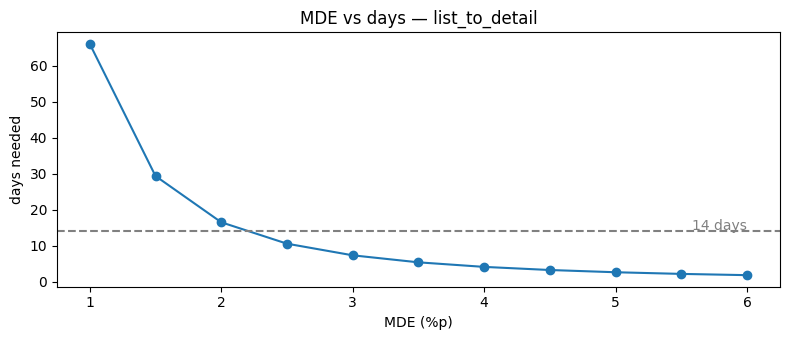

In [ ]:
# [1.5-C] 필요한 기간
# 실험 전 데이터에서 대상 사용자의 하루 평균 '분모 세션 수'를 구하고, 그룹당으로 환산하세요.

num_col, den_col = METRICS[PRIMARY]
daily_denominator = target_pre.groupby("day")[den_col].sum().mean()
TRAFFIC_SHARE = 1.0
daily_per_group = daily_denominator * TRAFFIC_SHARE / 2

n_per_group = n_per_group_naive * design_effect
days_needed = n_per_group / daily_per_group
print(f"그룹당 필요한 분모 세션(디자인 효과 반영): {n_per_group:,.0f}")
print(f"그룹당 하루 분모 세션: {daily_per_group:,.0f} → 계산상 {days_needed:.1f}일")

# MDE를 바꾸면 기간이 어떻게 달라지는지
mdes = np.arange(0.01, 0.061, 0.005)
days = [NormalIndPower().solve_power(proportion_effectsize(p0 + m, p0), alpha=ALPHA, power=POWER) * design_effect / daily_per_group for m in mdes]
plt.figure(figsize=(8, 3.5))
plt.plot(mdes * 100, days, marker="o")
plt.axhline(14, ls="--", c="gray"); plt.text(mdes[-1] * 100, 14.5, "14 days", ha="right", color="gray")
plt.xlabel("MDE (%p)"); plt.ylabel("days needed"); plt.title(f"MDE vs days — {PRIMARY}")
plt.tight_layout(); plt.show()

### Q1.5 표본과 기간

1. A/A 테스트 결과 두 그룹의 차이는 유의했나요? 유의하지 않아야 정상인 이유는?
2. 사용자 단위 표준오차가 세션 독립 가정 표준오차보다 큰 이유를 "같은 사람의 세션"이라는 말을 써서 설명하세요.
3. 계산상 필요한 일수와 **최종으로 정한 실험 기간**은 각각 며칠인가요? 계산값보다 길게 잡았다면 그 이유는?
4. MDE를 어떤 근거로 정했나요? (통계가 아닌 **비즈니스 관점**의 근거를 포함)
5. (선택) `PRIMARY`를 `search_to_complete`로 바꿔 다시 계산해보세요. 기간이 어떻게 달라지나요? 이것이 1.3의 지표 역할 선택에 어떤 의미가 있나요?

**답변:**
1. 두 그룹의 차이는 0.07%p, p-value 0.93으로 유의하지 않았고 95% 신뢰구간 [-1.45%p, +1.59%p]도 0을 포함했다. 사용자를 무작위로 나눴기 때문에 두 그룹은 같은 모집단에서 뽑힌 것과 같고, 차이가 있다면 우연이거나 배정, 분석 과정에 문제가 있다는 뜻이므로 유의하지 않아야 정상이다.
2. 같은 사람의 세션은 그 사람의 구매 성향이나 습관을 공유하기 때문에 결과가 비슷하게 움직인다. 그래서 세션 수만큼 독립적인 정보가 있는 게 아니라 실제 정보량은 더 적다. 세션을 독립적으로 보면 이 점을 무시해 표준오차를 과소추정하게 되고, 같은 사람의 세션을 묶어 계산하면 더 커진다.
3. 계산상 필요한 기간은 7.3일이지만 최종 기간은 14일로 정했다. 7.3일은 7일을 조금 넘는데, 평일과 주말의 사용 패턴이 다르기 때문에 요일 주기를 맞추려면 1주 단위로 끊어야 해서 2주로 잡았다. 또한 디자인 효과를 14일 기준 A/A로 추정했기 때문에 실험 기간도 같게 맞춰준다. 그리고 8일차부터 광고 캠페인이 시작돼 사용자 구성이 바뀌기 때문에 캠페인 전후를 각각 충분히 관찰할 시간이 필요하다.
4. 다른 채널과의 격차가 약 10%p인데, 3%p는 약 1/3을 줄이는 수준이다. 기준값 0.48 대비 상대적으로 약 6% 상승이라서 뒤 단계 전환율이 그대로라면 예약 수도 약 6% 늘어나서 목록 순서를 바꾸는 리스크를 감수할 만하다.
5. PRIMARY를 search_to_complete로 바꾸고, 목록 → 상세 3%p 상승(상대 약 6%)이 최종 전환까지 그대로 이어진다고 가정해 MDE를 0.8%p로 잡으면, 필요한 기간은 약 35.7일로 list_to_detail보다 약 5배 길어진다. 최종 전환율은 기준값이 0.13으로 낮고, 효과가 여러 퍼널 단계를 거치며 희석되어 같은 개선을 잡으려면 훨씬 많은 표본이 필요하기 때문이다. 따라서 B가 직접 바꾸는 list_to_detail을 Primary로 두고, search_to_complete는 효과를 증명하는 지표가 아니라 떨어지지 않는지 확인하는 Guardrail로 두는 것이 맞다.

## 1.6 실험 기간 중간에 외부 변화가 생긴다면?

마케팅팀에서 연락이 왔습니다. **실험 8일차부터 promotion 채널 대규모 광고 캠페인이 시작**되어 promotion 유입이 크게 늘어납니다.

1. 이 캠페인은 A그룹과 B그룹에 **똑같이** 영향을 줍니다. 그래도 실험 결과 해석에 문제가 생길까요? 무작위 배정의 성질로 설명하세요.
2. 캠페인으로 새로 들어오는 사용자는 평소 promotion 사용자와 어떻게 다를까요? 어떤 지표의 수준이 8일차 전후로 달라질까요?
3. 이 상황에서 설계를 바꾸거나 분석 계획에 추가할 것이 있다면? (캠페인을 피해 실험을 미루거나 줄이는 선택지도 검토)

**답변:**
1. 무작위 배정 덕분에 캠페인으로 들어온 사용자도 A와 B에 공평하게 나뉘므로 두 그룹의 차이는 편향 없이 효과를 추정한다. 하지만 실험 결과는 평소 사용자 + 캠페인 사용자가 섞인 집단에서의 평균 효과여서 두 집단에서 효과 크기가 다르다면 캠페인이 끝난 평상시의 효과와는 다를 수 있다.
2. 대규모 광고로 들어온 사용자는 평소 promotion 사용자보다 구매 의도가 약하고 앱에 덜 익숙할 가능성이 크다. 그래서 8일차부터 A/B 모두 list_to_detail과 그 뒤 단계 전환율의 수준이 함께 떨어질 것이다.
3. 캠페인을 피해 실험을 미루거나 7일로 줄이는 방법도 생각했지만, 7일로 줄이면 7.3일에 못 미치고, 캠페인 유입 사용자도 B가 겨냥하는 promotion 사용자라서 기간은 14일로 유지한다. 보조 분석으로 1-7일 vs 8-14일의 효과를 따로 보고, 두 기간의 효과 방향이 반대라면 배포 전 추가 검토를 한다.

## 1.7 사전 판정 규칙

결과를 보기 **전에** 아래 표를 채우세요. Part 2에서는 이 표대로 판정합니다.

| 상황 | 판정 |
|---|---|
| 데이터 품질(SRM) 검정 p < 0.001 |판정 중단 -> 지표를 보지 않고, 기기 별로 원인을 찾아 수정 후 재실험|
| Primary가 유의하게 개선 + 모든 Guardrail 유의한 악화 없음 |배포|
| Primary가 유의하게 개선 + Guardrail 중 하나라도 유의하게 악화 |배포 보류 -> 원인 분석 후 개선안 수정해 재실험|
| Primary 유의하지 않음 |배포하지 않음|
| (선택) 그 밖에 미리 정해두고 싶은 규칙 |모든 판정은 사용자 단위 표준오차의 p<0.05로 한다. 14일 고정, 중간에 결과를 보고 멈추지 않는다. Primary가 유의하게 악화되면 종료한다. 1-7일과 8-14일의 효과 방향이 반대면 배포 전 추가 검토한다.|

In [ ]:
# [1.8] 최종 설계서 — 위에서 정한 값을 그대로 옮기세요. 이 셀이 Part 2의 실험을 결정합니다.

my_design = {
    "idea":           "B",      # "A" | "B" | "C"
    "target":         "promotion",      # "promotion" | "all"
    "unit":           "user",      # "user" | "session"
    "primary_metric": PRIMARY,
    "guardrails":     ["detail_to_room", "search_to_complete"],      # 예: ["search_to_complete", "detail_to_room"]
    "secondary":      [],
    "alpha":          ALPHA,
    "power":          POWER,
    "mde_abs":        MDE,
    "traffic_share":  TRAFFIC_SHARE,
    "duration_days":  14,        # 1.5에서 정한 최종 기간 (3~42)
    "stopping":       "fixed",      # "fixed": 정한 기간까지 / "peek": 매일 확인하다 유의하면 중단
}
my_design

{'idea': 'B',
 'target': 'promotion',
 'unit': 'user',
 'primary_metric': 'list_to_detail',
 'guardrails': ['detail_to_room', 'search_to_complete'],
 'secondary': [],
 'alpha': 0.05,
 'power': 0.8,
 'mde_abs': 0.03,
 'traffic_share': 1.0,
 'duration_days': 14,
 'stopping': 'fixed'}

---
# Part 2. 실행과 판정

여기서부터는 Part 1을 수정하지 마세요. 아래 셀을 실행하면 **여러분의 설계대로** 실험이 진행됩니다.

In [ ]:
exp = run_experiment(my_design, SEED)
display(exp.head())

실험 기간: 2026-03-02 ~ 2026-03-15 (14일)
실험에 노출된 사용자: 11,208명 / 세션: 32,749개
참고: 실험 8일차(2026-03-09)부터 마케팅팀의 promotion 채널 대규모 광고 캠페인이 시작됐습니다.


,session_id,user_id,channel,device,user_type,day,session_start,group,search,list_view,detail_view,room_select,checkout,payment_complete,payment_method,amount,cancelled,net_amount
0,E00000000,200039,promotion,android,leisure,1,2026-03-02 10:18:41,A,1,1,0,0,0,0,None,0.0000,0,0.0000
1,E00000001,200070,promotion,android,leisure,1,2026-03-02 08:12:20,B,1,1,1,1,1,1,card,"204,400.0000",0,"204,400.0000"
2,E00000002,200072,promotion,android,business,1,2026-03-02 21:39:19,A,1,0,0,0,0,0,None,0.0000,0,0.0000
3,E00000003,200148,promotion,web,leisure,1,2026-03-02 12:05:43,B,1,1,0,0,0,0,None,0.0000,0,0.0000
4,E00000004,200148,promotion,web,leisure,1,2026-03-02 18:50:30,B,1,1,1,1,1,0,card,0.0000,0,0.0000


## 2.1 데이터 품질 — SRM 확인

결과 지표를 보기 전에 **배정 비율이 설계(50:50)대로인지** 먼저 확인합니다.

In [ ]:
from scipy.stats import chisquare

# 주석 빈칸: 배정 단위가 사용자이므로, 그룹별 고유 사용자 수를 세어야 한다.
counts = exp.groupby("group")["user_id"].nunique()
print(counts)

total = counts.sum()
srm_p = chisquare(counts.values, f_exp=[total * 0.5, total * 0.5]).pvalue
print(f"SRM 검정 p-value: {srm_p:.2e}  →  {'SRM 의심! 결과 해석을 멈추세요' if srm_p < 0.001 else '통과'}")

# 어디서 어긋났는지 보기: 기기별 그룹 사용자 수
display(exp.groupby(["device", "group"])["user_id"].nunique().unstack())

group
A    5874
B    5334
Name: user_id, dtype: int64
SRM 검정 p-value: 3.38e-07  →  SRM 의심! 결과 해석을 멈추세요


group,A,B
device,,
android,2413,2428
ios,2213,2238
web,1248,668


### Q2.1
1. SRM 검정 결과는? 통과하지 못했다면, 기기별 표에서 어디가 어긋났나요?
2. SRM이 있을 때 결과를 그대로 믿으면 안 되는 이유는? "어떤 사용자가 빠졌는가"의 관점에서 설명하세요.

**답변:**
1. SRM 검정 p-value는 3.38e-07로 기준보다 훨씬 작아 통과하지 못했다. 기기별로 보면 android(2,413 vs 2,428)와 ios(2,213 vs 2,238)는 거의 반반이지만, web은 A 1,248명, B 668명으로 B그룹 웹 사용자가 약 46% 적다. 웹 B그룹에서만 사용자가 빠졌으므로, B의 새 목록 화면이 일부 웹 브라우저에서 제대로 표시되지 않거나 로그가 수집되지 않았을 가능성이 크다.
2. 무작위 배정이 의미 있는 이유는 두 그룹이 비교 가능한 사용자로 구성되기 때문인데, SRM은 그 전제가 깨졌다는 신호다. 이번에는 무작위로 빠진 게 아니라 B그룹의 특정 웹 환경 사용자만 빠졌다. 만약 이들이 오래된 브라우저를 쓰는 등 전환율이 원래 낮은 사용자였다면, B에는 전환율이 높은 사용자만 남아 처치 효과가 없어도 B가 더 좋아 보인다. 즉 B와 A의 차이가 화면 효과인지, 빠진 사람들의 차이인지 구분할 수 없으므로 결과를 그대로 믿으면 안 된다.

## 2.2 지표 분석

`ratio_test(df, metric)`은 두 가지 표준오차를 함께 보여줍니다.
- `se_naive`, `p_naive`: 세션을 서로 독립인 관측으로 본 계산
- `se_delta`, `p_value`, `ci_low ~ ci_high`: 같은 사용자의 세션끼리 묶어서 계산 (**판정에는 이쪽을 사용**)

In [ ]:
# [2.2-A] Primary + Guardrail + Secondary 결과표
metrics_to_check = [my_design["primary_metric"]] + my_design["guardrails"] + my_design["secondary"]

results = pd.DataFrame([ratio_test(exp, m) for m in metrics_to_check])
display(results)

,metric,A,B,diff,rel_diff,ci_low,ci_high,p_value,se_delta,se_naive,p_naive
0,list_to_detail,0.4340,0.5022,0.0683,0.1574,0.0538,0.0828,0.0000,0.0074,0.0057,0.0000
1,detail_to_room,0.6808,0.6278,-0.0529,-0.0778,-0.0694,-0.0365,0.0000,0.0084,0.0080,0.0000
2,search_to_complete,0.1139,0.1206,0.0068,0.0593,-0.0013,0.0148,0.1004,0.0041,0.0036,0.0576


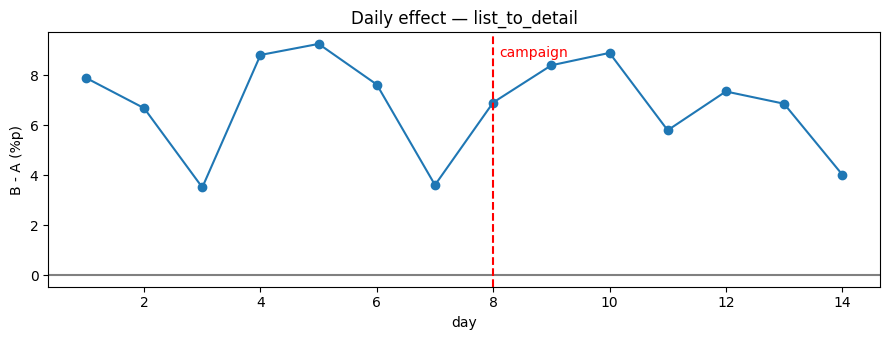

1~7일: diff=+0.0677, 95% CI [+0.0481, +0.0874]
8일~: diff=+0.0687, 95% CI [+0.0514, +0.0859]
1~7일: A=0.4804, B=0.5481
8일~: A=0.4012, B=0.4699


In [ ]:
# [2.2-B] 일별 Primary 효과 — 신규성 효과와 8일차(캠페인 시작) 전후 확인
num_col, den_col = METRICS[my_design["primary_metric"]]
daily = exp.groupby(["day", "group"]).agg(num=(num_col, "sum"), den=(den_col, "sum")).reset_index()
daily["rate"] = daily["num"] / daily["den"]

# 주석 빈칸: pivot 후 B - A를 계산하면 그날 하루의 처치 효과를 볼 수 있다.
daily_diff = daily.pivot(index="day", columns="group", values="rate")
daily_diff["diff"] = daily_diff["B"] - daily_diff["A"]

plt.figure(figsize=(9, 3.5))
plt.plot(daily_diff.index, daily_diff["diff"] * 100, marker="o")
plt.axhline(0, c="gray"); plt.axvline(8, ls="--", c="red"); plt.text(8.1, plt.ylim()[1] * 0.9, "campaign", color="red")
plt.xlabel("day"); plt.ylabel("B - A (%p)"); plt.title(f"Daily effect — {my_design['primary_metric']}")
plt.tight_layout(); plt.show()

# 전반부(1~7일) vs 후반부(8일~) 효과
for name, sub in [("1~7일", exp[exp["day"] <= 7]), ("8일~", exp[exp["day"] >= 8])]:
    r = ratio_test(sub, my_design["primary_metric"])
    print(f"{name}: diff={r['diff']:+.4f}, 95% CI [{r['ci_low']:+.4f}, {r['ci_high']:+.4f}]")

for name, sub in [("1~7일", exp[exp["day"] <= 7]), ("8일~", exp[exp["day"] >= 8])]:
    r = ratio_test(sub, "list_to_detail")
    print(f"{name}: A={r['A']:.4f}, B={r['B']:.4f}")


### Q2.2
1. Primary의 효과를 **점추정이 아니라 신뢰구간으로** 한 문장으로 말하세요. (예: "목록 → 상세 전환율이 ○%p에서 ○%p 사이로 올랐다")
2. `se_naive`와 `se_delta` 중 어느 쪽이 더 큰가요? naive로 판정했다면 어떤 위험이 있나요?
3. 일별 그래프에서 효과가 기간 내내 비슷한가요, 아니면 초반에 몰려 있나요? 어떤 의미인가요?
4. Guardrail 지표는 어떻게 나왔나요? "유의한 악화 없음"과 "변화 없음이 증명됨"은 같은 말인가요?
5. A그룹과 B그룹의 Primary 지표 **수준**이 8일차 전후로 어떻게 달라졌나요? 그런데도 A/B 비교가 유효한 이유는?

**답변:**
1. promotion 사용자의 list_view → detail_view 전환율은 B에서 5.4%p에서 8.3%p 사이로 올랐다.
2. 세 지표 모두 se_delta가 더 크다. navie는 같은 사람의 세션을 독립으로 봐서 표준오차를 과소추정하므로, 신뢰구간이 실제보다 좁아지고 우연한 차이를 유의하다고 잘못 판단할 위험이 커진다.
3. 효과는 3.5-9.3%p 사이에서 움직이지만 14일 내내 양수였고, 초반에 몰려 있지 않았다. 전반부와 후반부도 거의 같다. 새 화면이 신기해서 잠깐 클릭하는 신규성 효과보다는 목록 구조가 바뀌어 생긴 지속적인 행동 변화로 보인다.
4. detail_to_room은 5.3%p 하락으로 유의하게 악화됐다. 상세 페이지 진입은 늘었지만 객실 선택으로 이어지는 비율은 줄어, 1.1에서 예상한 조건에 맞지 않는 상단 숙소를 일단 눌러보고 나가는 질 낮은 클릭이 늘어난 것으로 보인다. search_to_complete는 유의하지 않았지만, 유의한 악화 없음은 변화 없음이 증명됨과 다르다. 신뢰구간이 −0.13%p - +1.48%p로 넓고, 1.5에서 계산했듯 이 지표의 작은 변화를 잡으려면 약 36일이 필요해 14일 실험으로는 검정력이 부족하다.
5. 캠페인 전에는 A 0.480, B 0.548이었고, 캠페인 후에는 A 0.401, B 0.470으로 두 그룹 모두 약 8%p씩 떨어졌다. 구매 의도가 약한 캠페인 유입 사용자가 늘어 전환율 수준 자체가 낮아졌기 때문이다. 하지만 무작위 배정 덕분에 이런 사용자가 A와 B에 고르게 들어가 두 그룹이 함께 움직였고, 차이(B − A)는 전반부 +6.77%p, 후반부 +6.87%p로 거의 같았다. A/B 테스트는 같은 기간, 같은 조건에서 두 그룹을 비교하기 때문에, 외부 변화로 수준이 바뀌어도 차이로 본 효과는 여전히 유효하다.

## 2.3 판정

1.7의 사전 판정 규칙을 그대로 적용하세요.

- **해당하는 규칙 행:** SRM 검정 p<0.001
- **판정:** 재실험
- **결정 메모 (3~5문장):** 효과 크기(신뢰구간) × 비용 × 리스크를 함께 고려해, 비개발자 동료가 읽어도 이해되게 쓰세요.
프로모션 숙소를 목록 맨 위에 고정했더니 상세 페이지를 여는 비율은 5-8%p 올랐지만, 상세를 본 뒤 객실을 고르는 비율은 4-7%p 떨어졌고 최종 예약이 늘었다는 근거는 없었다. 게다가 웹 일부 환경에서 B그룹 사용자가 약 절반 가까이 집계되지 않는 데이터 문제가 있어서 이 숫자 자체도 믿기 어렵다. 지금 배포하면 웹 사용자 일부가 화면을 제대로 못 볼 위험이 있고, 클릭만 늘고 예약은 안 늘 수 있다. 따라서 배포하지 않고, 웹 표시·로그 문제를 고친 뒤 다시 실험한다.
- **다음 실험 아이디어 (1개):** 이번 결과에서 새로 생긴 가설
상단 고정 숙소를 프로모션 여부만으로 정하지 말고, 사용자가 검색한 지역, 날짜, 가격 조건에 맞는 프로모션 숙소만 상단에 보여주면, 목록 → 상세 상승은 유지하면서 상세 → 객실 선택 하락을 막을 수 있을 것이다.

---
# Part 3. 심화 과제 — 아래 중 1개 선택

같은 사용자 데이터로 **설계 한 가지만 바꿔** 다시 실험하고, 결과가 왜 달라졌는지 분석하세요.

| 선택 | 바꿀 것 | 생각해볼 질문 |
|---|---|---|
| **A. 기간과 중단 규칙** | `duration_days`를 7로, 또는 `stopping`을 `"peek"`으로 | 언제 멈췄나? 효과 크기가 어떻게 달라졌나? 왜? |
| **B. 대상 범위** | `target`을 반대로 | 효과 크기와 표준오차가 어떻게 달라졌나? 어느 쪽이 의사결정에 유리한가? |
| **C. 배정 단위** | `unit`을 반대로 | 효과 크기가 왜 달라졌나? 사용자 경험 측면의 문제는? |

### 심화 과제 작성
- 선택한 항목: A
- 바꾼 설계 값: stopping: "fixed" -> "peek"
- 원래 결과 vs 바뀐 결과 (핵심 숫자 2~3개): 실험이 14일 대신 3일만에 조기 종료됐고, 노출 사용자도 11,208명에서 4,219명으로 줄었다. Primary 효과는 6.83%p 에서 6.02%p로 비슷했지만, 95% 신뢰구간 폭이 2.9%p에서 5.6%p로 약 2배 넓어졌다. Guardrail detail_to_room의 악화는 p<0.001에서 p=0.027로 간신히 유의해졌고, search_to_complete의 신뢰구간은 ±1.8%p 수준으로 넓어져 사실상 아무것도 말해주지 않는다.
- 왜 달라졌는가: 매일 결과를 보다가 처음 유의해지는 순간 멈추는 규칙이라서 B처럼 효과가 큰 경우 첫 확인일에 바로 멈춘다. 표본이 1/3 수준이라 신뢰구간이 넓어지고, Guardrail처럼 작은 변화를 잡아야 하는 지표는 검정력이 크게 떨어진다. 또한 3일은 요일 주기도 못 채우고, 8일차부터 시작된 캠페인 기간 데이터가 아예 없어 캠페인 유입 사용자에게도 효과가 유지되는지 확인할 수 없다. 이번에는 효과가 실제로 커서 방향은 맞았지만, 효과가 없거나 작은 경우에 매일 확인하며 p < 0.05에서 멈추면 우연한 순간을 유의하다고 잡을 확률이 5%보다 훨씬 커진다. 게다가 시뮬레이터의 중간 확인은 세션을 독립으로 보는 표준오차로 판단하므로 그 위험이 더 크다.
- 실무에서 이 교훈을 적용한다면: 실험 기간은 결과를 보기 전에 정하고, 최소 1주 단위로 끝까지 돌린다. 중간에 꼭 확인해야 한다면 O’Brien-Fleming 같은 순차 검정으로 중간 확인용 유의수준을 엄격하게 잡는다. 특히 Primary가 빨리 유의해져도 Guardrail은 더 많은 표본이 필요하므로, Primary가 유의하다는 이유만으로 멈추지 않는다.

In [ ]:
# [심화 과제 Skeleton]
alt_design = dict(my_design)
alt_design["stopping"] = "peek"      # 바꿀 설계 하나

alt = run_experiment(alt_design, SEED)
alt_results = pd.DataFrame([ratio_test(alt, m) for m in metrics_to_check])
display(pd.concat({"원래 설계": results.set_index("metric"), "바꾼 설계": alt_results.set_index("metric")}, axis=1))

실험 기간: 2026-03-02 ~ 2026-03-04 (3일 · 중간 확인 규칙으로 조기 종료)
실험에 노출된 사용자: 4,219명 / 세션: 5,757개
참고: 실험 8일차(2026-03-09)부터 마케팅팀의 promotion 채널 대규모 광고 캠페인이 시작됐습니다.


원래 설계                                                  \
                        A      B    diff rel_diff  ci_low ci_high p_value   
metric                                                                      
list_to_detail     0.4340 0.5022  0.0683   0.1574  0.0538  0.0828  0.0000   
detail_to_room     0.6808 0.6278 -0.0529  -0.0778 -0.0694 -0.0365  0.0000   
search_to_complete 0.1139 0.1206  0.0068   0.0593 -0.0013  0.0148  0.1004   

                                              바꾼 설계                          \
                   se_delta se_naive p_naive      A      B    diff rel_diff   
metric                                                                        
list_to_detail       0.0074   0.0057  0.0000 0.4819 0.5422  0.0602   0.1250   
detail_to_room       0.0084   0.0080  0.0000 0.7055 0.6657 -0.0397  -0.0563   
search_to_complete   0.0041   0.0036  0.0576 0.1320 0.1331  0.0011   0.0085   

                                                                      
                    ci_low ci_high p_value se_delta se_naive p_naive  
metric                                                                
list_to_detail      0.0321  0.0884  0.0000   0.0144   0.0137  0.0000  
detail_to_room     -0.0750 -0.0045  0.0272   0.0180   0.0179  0.0261  
search_to_complete -0.0167  0.0189  0.9017   0.0091   0.0089  0.9001

---
# Part 4. 회고

- 설계 단계에서 가장 고민했던 결정과 그 이유: 실험 기간을 정하는 게 가장 고민됐다. 계산상으로는 7.3일이면 충분했지만, 8일차부터 광고 캠페인이 시작되었기 때문에 캠페인을 피해 7일로 줄이면 계산값에도 못 미치고 요일 주기도 못 채우며, 캠페인 유입 사용자도 결국 이 실험이 겨냥하는 promotion 사용자라서 14일로 유지했다.
- 결과를 보고 "설계를 바꾸고 싶다"고 느낀 순간이 있었나요? 있었다면 무엇이었나요? Primary인 목록 → 상세 전환율이 +6.8%p로 목표(3%p)의 두 배 넘게 나왔을 때, SRM 결과를 무시하고 그래도 효과는 확실하니 배포해도 되지 않을까하는 생각이 들었다.
- 진단 결과를 실험으로 검증해보며 새로 알게 된 점 (다음 그로스 세션에서는 이런 진단을 직접 하는 법을 배웁니다): 진단이 맞아도 처방이 맞는다는 보장은 없다는 것을 알게 되었다. 분석팀 진단대로 목록 → 상세 단계가 병목이었고 B는 그 단계를 실제로 크게 개선했지만, 그 뒤 단계인 상세 → 객실 선택이 떨어져 최종 예약이 늘었다는 근거는 없었다. 한 단계 지표만 보면 성공처럼 보여도, 퍼널 전체에서는 문제를 다음 단계로 옮겨놓은 것일 수 있다. 그래서 진단할 때도 왜 이 단계에서 이탈하는가를 더 깊이 봐야 한다는 걸 느꼈다.
- 가장 어려웠던 부분: 표본 크기 계산에서 MDE를 정하는 부분이 어려웠다. 특히 search_to_complete로 기간을 다시 계산할 때 처음에 MDE를 3%p 그대로 넣어서 오히려 기간이 2.7일로 짧게 나왔는데, 기준값이 0.13인 지표에서 3%p는 상대적으로 23%나 되는 비현실적인 효과라는 걸 나중에 알았다. 같은 개선을 비교하려면 상대 효과를 맞춰야 했고, 그렇게 다시 계산하니 35.7일이 나왔다.

---
# Part 5. 제출 전 체크리스트

- [ ] Q0에서 실험이 필요한 처방과 바로 고쳐야 하는 처방을 구분했는가?
- [ ] 가설에 바꾸는 것, 행동 메커니즘, 지표와 방향이 모두 있는가?
- [ ] 모든 지표의 분자 / 분모 / Grain / Window를 명시했는가?
- [ ] 배정 단위와 분석 단위의 차이를 고려했는가? (A/A 테스트, 디자인 효과)
- [ ] MDE를 비즈니스 근거로 정했고, 기간을 계산값보다 짧지 않게 정했는가?
- [ ] 판정 규칙을 결과를 보기 전에 정했고, 결과를 본 뒤 Part 1을 수정하지 않았는가?
- [ ] SRM을 가장 먼저 확인했는가?
- [ ] 효과를 신뢰구간으로 말했는가?
- [ ] 기술블로그에 옮길 설계서, 그래프, 결정 메모를 정리했는가?
- [ ] 마지막 셀에 AI 활용 방법과 대화 내역을 붙였는가?

---
# Part 6. 생성형 AI 활용 방법 + 대화 내역 (필수)

AI를 사용했다면 아래를 작성하고, **대화 내역을 붙여넣으세요.** 사용하지 않았다면 "사용하지 않음"이라고 적어주세요.

1. 어느 문항에서, 어떤 목적으로 AI를 썼나요?
- Q1.5-5에서 search_to_complete를 Primary로 바꿨을 때 기간이 왜 달라지는지 해석하는 데 사용했다. 처음에 MDE를 3%p 그대로 넣어 2.7일이 나왔는데, AI와 이야기하며 기준값이 다른 지표는 상대 효과를 맞춰 MDE를 0.8%p로 잡아야 공정한 비교가 된다는 걸 확인하고 다시 계산했다.
- 1.7 사전 판정 규칙: 각 상황에서 판정 뒤에 어떤 행동을 할지 구체화하는 데 AI 피드백을 받았다.
- Q2.2-5: 캠페인 전후 A/B 전환율 수준을 따로 뽑는 코드를 AI에게 받아 실행했고, 결과 해석 문장을 다듬었다.
- Part 3 심화 과제: peek 규칙으로 바꾼 결과를 원래 결과와 비교, 해석하는 데 AI 초안을 활용했다.
2. AI의 답 중 **본인 데이터로 확인해보니 틀렸거나 맞지 않았던 것**이 있었나요?
심화 과제에서 AI는 매일 확인하다 멈추면 일찍 멈춘 시점의 효과가 우연히 크게 나올 가능성이 높다고 했지만, 실제로는 3일차에 멈춘 효과가 +6.02%p로 14일 결과(+6.83%p)보다 오히려 작았다. B의 효과가 실제로 크고 꾸준했기 때문이었고, 그래서 결론을 효과 과장이 아니라 신뢰구간이 약 2배 넓어지고, Guardrail 검정력과 캠페인 기간 관찰을 잃는다로 바꿔 썼다.
3. 이번 과제에서 AI에게 맡길 수 없었던, **사람이 직접 판단해야 했던 결정**은 무엇이었나요?
어떤 아이디어로 실험할지와 결과를 본 뒤의 판정이다. Primary가 +6.8%p로 크게 나와 배포하고 싶은 마음이 들었지만, 사전에 정한 규칙대로 SRM 행을 적용해 재실험으로 판정하는 것은 내가 지켜야 하는 약속이었다.

### 대화 내역
(**① Q1.5-5**
나: PRIMARY를 search_to_complete로 바꾸고 MDE 0.03으로 돌렸더니 2.7일이 나왔어. 왜 기간이 더 짧아?
AI: 기준값 0.13에서 3%p는 상대 약 23% 상승이라 아주 큰 효과를 가정한 거예요. list_to_detail에서 3%p는 상대 약 6%니까, 같은 개선을 비교하려면 상대 효과를 맞춰 MDE를 0.13 × 0.06 ≈ 0.8%p로 잡아야 해요.
나: 0.008로 바꾸니까 35.7일 나왔어.
AI: 기준값이 낮고 효과가 여러 단계를 거치며 희석돼서 그래요. 그래서 이 지표는 효과를 증명하는 Primary보다 악화 여부를 보는 Guardrail이 맞아요.

**② 1.7 사전 판정 규칙**
나: 판정 규칙 표를 "판정 중단 / 배포 / 배포 보류 / 배포하지 않음"으로 채웠는데 괜찮아?
AI: 판정 뒤에 무엇을 할지가 빠져 있어요. SRM이면 어디서 어긋났는지 확인하고 수정 후 재실험, Guardrail 악화면 원인 분석 후 개선안 수정 같은 후속 행동을 적어 두면 결과를 본 뒤 흔들리지 않아요. 판정에 쓸 표준오차(사용자 단위)와 기간 고정 여부도 미리 적어 두세요.

**③ Q2.2-5**
나: 8일차 전후로 A, B 각각의 list_to_detail 수준을 보고 싶어.
AI: 기존 반복문에서 ratio_test 결과의 A, B를 출력하면 돼요.
    for name, sub in [("1~7일", exp[exp["day"] <= 7]), ("8일~", exp[exp["day"] >= 8])]:
        r = ratio_test(sub, "list_to_detail")
        print(f"{name}: A={r['A']:.4f}, B={r['B']:.4f}")
나: 1~7일 A 0.4804 B 0.5481, 8일~ A 0.4012 B 0.4699 나왔어.
AI: 두 그룹 모두 약 8%p씩 떨어졌지만 차이는 거의 같아요. 무작위 배정으로 캠페인 유입 사용자가 양쪽에 고르게 들어갔기 때문에 차이로 본 효과는 여전히 유효해요.

**④ Part 3 (peek)**
나: peek으로 바꾸니까 3일 만에 멈췄어. 어떻게 해석해?
AI: 매일 보다가 처음 유의할 때 멈추면 우연히 효과가 커 보이는 순간에 멈추기 쉬워서 효과가 과장될 가능성이 높아요.
나: 3일차 효과가 +6.02%p로 14일(+6.83%p)보다 오히려 작아.
AI: 실제 효과가 크고 꾸준해서 과장이 드러나지 않은 경우예요. 이번 데이터에서는 신뢰구간 폭이 2.9%p에서 5.6%p로 넓어지고, Guardrail 검정력이 떨어지고, 캠페인 기간을 아예 못 본다는 점을 중심으로 쓰는 게 맞아요.)